# Data Structures & Algorithms: Dynamic Programming

> **Who is this for:** a beginner who can write Python functions and simple recursion, and a university student preparing for algorithm exams or coding interviews, where dynamic programming (DP) is the most-feared topic. It does not need to be.
>
> **What you will learn:**
> - what DP is: **overlapping subproblems** + **optimal substructure**
> - **top-down memoisation** vs. **bottom-up tabulation**, with a Fibonacci recursion tree, timings and **space optimisation**
> - a five-step **recipe** (state, transition, base case, order, answer) that you will apply to 16 classic problems
> - 1-D problems: climbing stairs, house robber, coin change (min coins and number of ways), decode ways
> - 2-D problems: grid paths with obstacles, minimum path sum, 0/1 knapsack (with item reconstruction), LCS, edit distance (with the alignment), LIS in O(n²) and O(n log n), matrix-chain multiplication, longest palindromic subsequence, partition equal subset sum, word break
> - bitmask DP (travelling salesman, Held-Karp) and DP on trees, briefly
> - where DP lives inside AI: Viterbi for HMMs, edit distance in NLP metrics, Bellman equations in RL, sequence alignment
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb), recursion and Big-O from [`01_complexity_analysis_and_recursion.ipynb`](01_complexity_analysis_and_recursion.ipynb), and [`08_greedy_and_divide_and_conquer.ipynb`](08_greedy_and_divide_and_conquer.ipynb) (greedy vs. DP, coin change with {1, 3, 4}).
>
> **Time needed:** about 3-4 hours (it is a long notebook; each problem section stands alone).
>
> **Runs on:** CPU, no API key, no internet. Executes in under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

**Dynamic programming** (DP) is a fancy name for a simple habit: never work out the same thing twice; write the answer down and reuse it. If a friend has just counted eight `+1`s and you add one more, they say 9 at once instead of counting again, because they remember the 8. Many problems break into smaller sub-problems that keep coming back, and DP solves each one once and stores it in a table. Climbing stairs one or two steps at a time is a good picture: the number of ways to reach step 5 is just the ways to reach step 4 plus the ways to reach step 3, so you fill in a small table from the bottom up. This can turn a job that would take billions of steps into a few thousand. DP is behind spell checkers, route planning, DNA comparison, speech recognition and the maths of reinforcement learning.

**Tiny example.** In the Fibonacci numbers each number is the sum of the two before it: 0, 1, 1, 2, 3, 5, 8. Computing F(6) with plain recursion makes 25 function calls and works out F(2) five separate times. With DP you fill a table once, left to right: 0, 1, 1, 2, 3, 5, 8. That is only 7 entries, and the last one gives F(6) = 8.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Dynamic programming | solve each small sub-problem once, store it, reuse it | route planners, DNA alignment, the Bellman equations of reinforcement learning |
| Memoisation (top-down) | remember answers in a notebook as you go | caching slow function calls with `functools.lru_cache` |
| Edit distance | the fewest letter changes that turn one word into another | spell-check suggestions, the word error rate used to score speech recognition |

## Table of contents

1. What is dynamic programming?
2. Fibonacci: the recursion tree and repeated work
3. Top-down memoisation vs. bottom-up tabulation (with timings and space optimisation)
4. The DP recipe: state, transition, base case, order, answer
5. 1-D problems: climbing stairs, house robber, coin change, decode ways
6. 2-D problems: grid paths, minimum path sum, 0/1 knapsack, LCS, edit distance, LIS, matrix-chain multiplication, longest palindromic subsequence, partition equal subset sum, word break
7. Bitmask DP: the travelling salesman problem
8. DP on trees
9. How DP connects to AI: Viterbi, edit-distance metrics, Bellman equations, sequence alignment
10. Recap, practice problems, further reading

In [1]:
import bisect                      # binary search for the O(n log n) LIS
import itertools                   # brute-force checkers (subsets, permutations)
import math
import random
import sys
import time
from functools import lru_cache    # built-in memoisation decorator

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

random.seed(7)
np.random.seed(7)
print("Ready. Python recursion limit:", sys.getrecursionlimit())

Ready. Python recursion limit: 1000


## 1. What is dynamic programming?

> 💡 **In plain English:** dynamic programming means solving each small sub-problem once, writing the answer down and reusing it instead of recomputing it.

**Analogy.** Ask a friend "what is 1+1+1+1+1+1+1+1?" They count: 8. Now write "+1" at the end and ask again. They answer 9 instantly, because they *remembered* the previous answer instead of recounting. That is dynamic programming: **never solve the same subproblem twice; store the answer and reuse it.**

**Dynamic programming** (Richard Bellman, 1950s) is a technique for problems that have two properties:

| Property | Meaning | Example (Fibonacci) |
|---|---|---|
| **Optimal substructure** | the (optimal) answer can be built from (optimal) answers to smaller subproblems | `F(n) = F(n−1) + F(n−2)` |
| **Overlapping subproblems** | a naive recursion meets the **same** subproblems again and again | `F(n−2)` is needed by both `F(n)` and `F(n−1)` |

If subproblems do *not* overlap (merge sort), plain divide & conquer is enough (notebook 08). If the problem also has the **greedy-choice property**, a greedy algorithm is enough. DP is the general tool in between: it effectively tries **all** choices, but each subproblem is solved only once.

The name is historical: "programming" meant planning/filling a table (as in "linear programming"), not writing code.

## 2. Fibonacci: the recursion tree and repeated work

> 💡 **In plain English:** the plain recursive Fibonacci function recomputes the same values again and again, which is exactly the waste DP removes.

`F(0) = 0, F(1) = 1, F(n) = F(n−1) + F(n−2)`. The direct recursive code is correct but slow. Let us draw its **recursion tree** for `F(6)` and colour each call by which subproblem it computes.

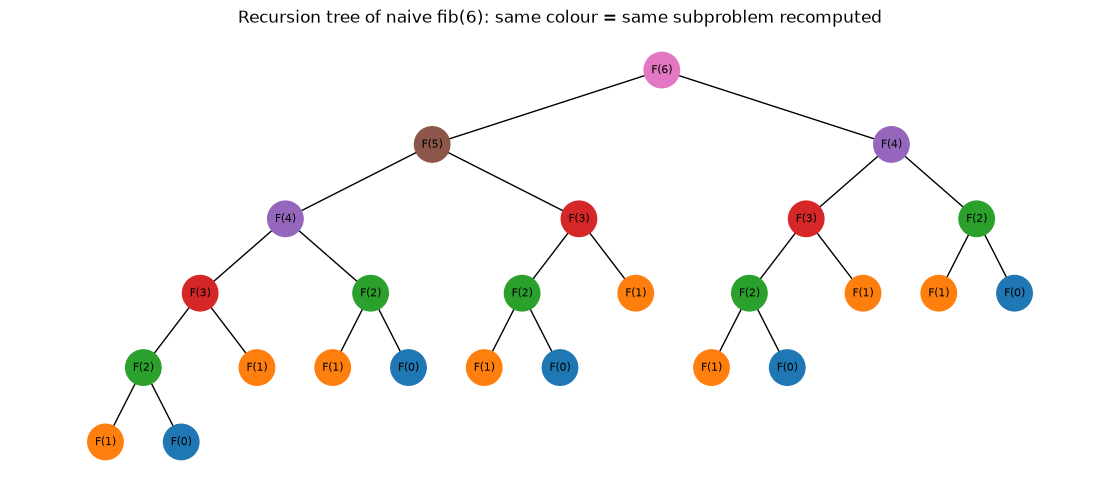

times each F(k) is computed while evaluating F(6): {6: 1, 5: 1, 4: 2, 3: 3, 2: 5, 1: 8, 0: 5}
total calls: 25


In [2]:
def fib_naive(n, counter):
    counter[n] = counter.get(n, 0) + 1     # count how many times each F(k) is computed
    if n < 2:
        return n
    return fib_naive(n - 1, counter) + fib_naive(n - 2, counter)


def recursion_tree(n):
    # Build the call tree of fib_naive(n) as a networkx graph with a tidy layout
    G, pos, labels = nx.DiGraph(), {}, {}
    next_x = itertools.count()
    def build(k, depth):
        node = len(labels)                 # unique id per call
        labels[node] = k
        G.add_node(node)
        kids = [build(k - 1, depth + 1), build(k - 2, depth + 1)] if k >= 2 else []
        for c in kids:
            G.add_edge(node, c)
        # leaves get the next free x; parents sit above the middle of their children
        pos[node] = (next(next_x), -depth) if not kids else ((pos[kids[0]][0] + pos[kids[-1]][0]) / 2, -depth)
        return node
    build(n, 0)
    return G, pos, labels


G, pos, labels = recursion_tree(6)
palette = plt.cm.tab10
colours = [palette(labels[v] % 10) for v in G]
plt.figure(figsize=(11, 4.5))
nx.draw(G, pos, labels={v: f"F({labels[v]})" for v in G}, node_color=colours,
        node_size=650, font_size=8, arrows=False)
plt.title("Recursion tree of naive fib(6): same colour = same subproblem recomputed")
plt.show()

counter = {}
fib_naive(6, counter)
print("times each F(k) is computed while evaluating F(6):", dict(sorted(counter.items(), reverse=True)))
print("total calls:", sum(counter.values()))

**What just happened?** The tree has 25 calls for `F(6)`, but only 7 *distinct* subproblems (`F(0)..F(6)`). `F(2)` alone is computed 5 times. The number of calls grows like `φⁿ` with `φ ≈ 1.618` (the golden ratio), i.e. **exponentially**, even though only `n + 1` different values exist. That gap is exactly what DP removes.

## 3. Top-down memoisation vs. bottom-up tabulation

> 💡 **In plain English:** you can keep the recursion and remember answers (top-down), or fill a table from the smallest case upwards (bottom-up).

There are two ways to "solve each subproblem once":

| | **Top-down (memoisation)** | **Bottom-up (tabulation)** |
|---|---|---|
| How | keep the natural recursion, but cache results in a dict/array ("memo") | fill a table iteratively from the smallest subproblems up |
| Order of solving | automatic, driven by recursion | you must choose an order where dependencies are ready |
| Solves | only the subproblems actually reached | usually every subproblem in the table |
| Overhead | function calls; Python's recursion limit (default 1000) | plain loops, usually faster in Python |
| Space optimisation | hard | easy: keep only the rows/values still needed |
| Easiest to write when | the recurrence is obvious but the order is not | the order is obvious (left to right, row by row) |

In [3]:
def fib_memo(n, memo=None):
    # Top-down: recursion + a dictionary of already-solved subproblems
    if memo is None:
        memo = {}
    if n < 2:
        return n
    if n not in memo:                              # solve each subproblem once
        memo[n] = fib_memo(n - 1, memo) + fib_memo(n - 2, memo)
    return memo[n]


@lru_cache(maxsize=None)                           # Python's built-in memoisation
def fib_lru(n):
    return n if n < 2 else fib_lru(n - 1) + fib_lru(n - 2)


def fib_tab(n):
    # Bottom-up: fill table[0..n] from small to large
    if n < 2:
        return n
    table = [0] * (n + 1)
    table[1] = 1
    for i in range(2, n + 1):
        table[i] = table[i - 1] + table[i - 2]    # dependencies already filled
    return table[n]


def fib_O1(n):
    # Space-optimised: only the last two values are ever needed
    prev, cur = 0, 1
    for _ in range(n):
        prev, cur = cur, prev + cur
    return prev


for n in range(25):
    assert fib_naive(n, {}) == fib_memo(n) == fib_lru(n) == fib_tab(n) == fib_O1(n)
print("all five versions agree for n = 0..24; F(90) =", fib_O1(90))

all five versions agree for n = 0..24; F(90) = 2880067194370816120


    naive calls  naive (ms)  memo (ms)  tabulation (ms)  O(1) space (ms)
n                                                                       
5            15      0.0067     0.0030           0.0016           0.0008
10          177      0.0582     0.0062           0.0022           0.0011
15         1973      0.7294     0.0096           0.0033           0.0017
20        21891     20.3162     0.0122           0.0042           0.0022
25       242785    212.8657     0.0166           0.0053           0.0029
28      1028457    729.4066     0.0180           0.0056           0.0030


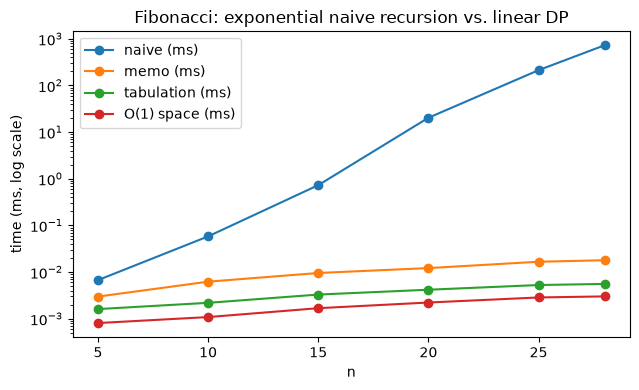

In [4]:
def timed(fn, *args, repeats=3):
    best = math.inf
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(*args); best = min(best, time.perf_counter() - t0)
    return best

def naive_calls(n):
    counter = {}
    fib_naive(n, counter)
    return sum(counter.values())                  # total number of calls made

ns = [5, 10, 15, 20, 25, 28]
rows = []
for n in ns:
    rows.append({"n": n,
                 "naive calls": naive_calls(n),
                 "naive (ms)": timed(fib_naive, n, {}, repeats=1) * 1000,
                 "memo (ms)": timed(fib_memo, n) * 1000,
                 "tabulation (ms)": timed(fib_tab, n) * 1000,
                 "O(1) space (ms)": timed(fib_O1, n) * 1000})
df = pd.DataFrame(rows).set_index("n")
print(df.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4))
for col in ["naive (ms)", "memo (ms)", "tabulation (ms)", "O(1) space (ms)"]:
    ax.plot(df.index, df[col], marker="o", label=col)
ax.set_yscale("log"); ax.set_xlabel("n"); ax.set_ylabel("time (ms, log scale)")
ax.set_title("Fibonacci: exponential naive recursion vs. linear DP"); ax.legend()
plt.tight_layout(); plt.show()

**What just happened?** The naive call count multiplies by about 1.6 every time `n` grows by one (1,028,457 calls for `n = 28`), and its time shoots up on the log-scale plot, while all three DP versions stay in the microseconds. Among the DP versions, plain loops (tabulation) usually beat recursion with a cache in Python because function calls are expensive.

Top-down has one more practical problem in Python: deep recursion. A demonstration (the error is deliberate and caught):

In [5]:
try:
    fib_memo(5000)                       # needs about 5000 nested calls
except RecursionError as e:
    print("RecursionError:", e)
print("bottom-up has no such limit: F(5000) has", len(str(fib_O1(5000))), "digits")

RecursionError: maximum recursion depth exceeded
bottom-up has no such limit: F(5000) has 1045 digits


| Version | Time | Extra space |
|---|---|---|
| naive recursion | Θ(φⁿ) ≈ O(1.618ⁿ) | O(n) call stack |
| memoisation | Θ(n) | O(n) memo + O(n) stack |
| tabulation | Θ(n) | O(n) table |
| space-optimised | Θ(n) | **O(1)** |

> ⚠️ **Common mistake:** using a mutable default argument as a memo (`def f(n, memo={})`) shares the cache across *all* calls, including calls for different inputs (e.g. a different coin list). Pass the memo explicitly or use `lru_cache` inside a wrapper function, as below.

## 4. The DP recipe

> 💡 **In plain English:** every DP solution answers the same five questions: what a table cell means, how to fill it, where to start, in which order, and where the answer is.

Every DP solution in this notebook is designed with the same five steps. Write them down **before** coding.

| Step | Question to answer | Fibonacci |
|---|---|---|
| 1. **State** | What does `dp[i]` (or `dp[i][j]`) mean, *in words*? | `dp[i]` = the i-th Fibonacci number |
| 2. **Transition** | How is a state computed from smaller states? (the recurrence; usually "try every last choice") | `dp[i] = dp[i−1] + dp[i−2]` |
| 3. **Base case(s)** | Which states are known without recursion? | `dp[0] = 0, dp[1] = 1` |
| 4. **Order** | In which order can the table be filled so dependencies are ready? | `i = 2, 3, …, n` |
| 5. **Answer** | Which state (or combination of states) is the final answer? | `dp[n]` |

Then: **complexity = (number of states) × (work per transition)**, and check whether only the last row/few values are needed (space optimisation).

> 🎓 **Exam / interview tip:** say the state definition out loud in plain English ("dp[i] is the minimum number of coins needed to make amount i"). Most wrong DP solutions come from a vague state.

Every problem below states the five steps, implements the DP, and is **checked against a brute-force solution on random small inputs**.

## 5. One-dimensional DP

> 💡 **In plain English:** problems where the answer for step i needs only a few earlier steps, like counting ways to climb stairs or making change with the fewest coins.

### 5a. Climbing stairs

You climb a staircase of `n` steps, taking **1 or 2 steps** at a time. How many distinct ways are there to reach the top?

- **State:** `dp[i]` = number of ways to reach step `i`.
- **Transition:** the last move was a 1-step (from `i−1`) or a 2-step (from `i−2`): `dp[i] = dp[i−1] + dp[i−2]`.
- **Base:** `dp[0] = 1` (one way to stand still), `dp[1] = 1`.
- **Order:** increasing `i`. **Answer:** `dp[n]`.

By hand: `dp = 1, 1, 2, 3, 5, 8` for `n = 0..5`, so 8 ways for 5 steps. It is Fibonacci shifted by one.

In [6]:
def climb_stairs(n):
    dp = [0] * (n + 1)
    dp[0] = 1
    for i in range(1, n + 1):
        dp[i] = dp[i - 1] + (dp[i - 2] if i >= 2 else 0)
    return dp[n]


def climb_brute(n):
    # Count all sequences of 1s and 2s that sum to n
    if n == 0:
        return 1
    return climb_brute(n - 1) + (climb_brute(n - 2) if n >= 2 else 0)


print([climb_stairs(n) for n in range(8)])
for n in range(20):
    assert climb_stairs(n) == climb_brute(n) == fib_O1(n + 1)
print("climb_stairs matches brute force for n = 0..19")

[1, 1, 2, 3, 5, 8, 13, 21]
climb_stairs matches brute force for n = 0..19


**Complexity:** Θ(n) time, Θ(n) space (Θ(1) with two variables, as in `fib_O1`).

### 5b. House robber

Houses in a row contain money `a[0..n−1]`. You cannot rob two **adjacent** houses. Maximise the money.

- **State:** `dp[i]` = best total using houses `0..i−1` (the first `i` houses).
- **Transition:** either skip house `i−1` (`dp[i−1]`) or rob it and skip `i−2` (`dp[i−2] + a[i−1]`): `dp[i] = max(dp[i−1], dp[i−2] + a[i−1])`.
- **Base:** `dp[0] = 0`, `dp[1] = a[0]`. **Order:** increasing `i`. **Answer:** `dp[n]`.

Worked example `a = [2, 7, 9, 3, 1]`:

| i | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| dp[i] | 0 | 2 | 7 | 11 | 11 | 12 |

Answer 12 (rob houses with 2, 9 and 1). Note that greedy "take the biggest first" would take 9, then 2... and is not reliable in general.

In [7]:
def house_robber(a):
    prev2, prev1 = 0, 0                    # dp[i-2], dp[i-1]  (space-optimised)
    for x in a:
        prev2, prev1 = prev1, max(prev1, prev2 + x)
    return prev1


def robber_brute(a):
    best = 0
    for mask in range(1 << len(a)):        # every subset of houses
        if mask & (mask >> 1) == 0:        # no two adjacent bits set = no adjacent houses
            best = max(best, sum(a[i] for i in range(len(a)) if mask >> i & 1))
    return best


print(house_robber([2, 7, 9, 3, 1]))
for _ in range(500):
    a = [random.randint(0, 20) for _ in range(random.randint(0, 12))]
    assert house_robber(a) == robber_brute(a)
print("house_robber matches brute force on 500 random streets")

12


house_robber matches brute force on 500 random streets


**Complexity:** Θ(n) time, Θ(1) space.

### 5c. Coin change: minimum number of coins, and number of ways

Coins of given values (unlimited supply), target amount `A`.

**(i) Minimum coins.**
- **State:** `dp[a]` = fewest coins that make amount `a` (∞ if impossible).
- **Transition:** the last coin is some `c ≤ a`: `dp[a] = 1 + min_c dp[a − c]`.
- **Base:** `dp[0] = 0`. **Order:** `a = 1..A`. **Answer:** `dp[A]`.

With coins {1, 3, 4} and `A = 6`, DP gives 2 (3 + 3), where greedy gave 3 in notebook 08.

**(ii) Number of ways** (combinations: `1+2` and `2+1` count once).
- **State:** `ways[a]` = number of multisets of coins summing to `a`, using the coins processed so far.
- **Transition:** for each coin `c` (outer loop), for `a = c..A` (inner loop): `ways[a] += ways[a − c]`.
- **Base:** `ways[0] = 1`. **Answer:** `ways[A]`.

Coins {1, 2, 5}, `A = 5`: the 4 ways are 5, 2+2+1, 2+1+1+1, 1+1+1+1+1.

> ⚠️ **Common mistake:** swapping the loops (amount outer, coin inner) counts **ordered** sequences (permutations): `1+2` and `2+1` become different. Both are valid problems, so read the question carefully.

In [8]:
def min_coins(coins, A):
    dp = [0] + [math.inf] * A
    for a in range(1, A + 1):
        for c in coins:
            if c <= a:
                dp[a] = min(dp[a], dp[a - c] + 1)      # use coin c last
    return dp[A] if dp[A] != math.inf else -1         # -1 means impossible


def count_ways(coins, A):
    ways = [1] + [0] * A
    for c in coins:                                    # coin loop OUTSIDE -> combinations
        for a in range(c, A + 1):
            ways[a] += ways[a - c]
    return ways[A]


def count_ordered(coins, A):
    ways = [1] + [0] * A
    for a in range(1, A + 1):                          # amount loop OUTSIDE -> ordered sequences
        for c in coins:
            if c <= a:
                ways[a] += ways[a - c]
    return ways[A]


def coins_brute(coins, A):
    # Enumerate every multiset (count of each coin) that sums to A
    best, n_ways = math.inf, 0
    ranges = [range(A // c + 1) for c in coins]
    for counts in itertools.product(*ranges):
        if sum(k * c for k, c in zip(counts, coins)) == A:
            n_ways += 1
            best = min(best, sum(counts))
    return (best if best != math.inf else -1), n_ways


print("min coins {1,3,4}, 6:", min_coins([1, 3, 4], 6))
print("ways {1,2,5}, 5:", count_ways([1, 2, 5], 5), "| ordered sequences:", count_ordered([1, 2, 5], 5))
for _ in range(300):
    coins = random.sample(range(1, 12), random.randint(1, 4))
    A = random.randint(0, 30)
    assert (min_coins(coins, A), count_ways(coins, A)) == coins_brute(coins, A)
print("min_coins and count_ways match brute force on 300 random instances (incl. impossible ones)")

min coins {1,3,4}, 6: 2
ways {1,2,5}, 5: 4 | ordered sequences: 9


min_coins and count_ways match brute force on 300 random instances (incl. impossible ones)


**What just happened?** Min coins for 6 with {1, 3, 4} is 2; there are 4 combinations for 5 with {1, 2, 5} but 9 *ordered* sequences; both DPs match the brute force, including amounts that cannot be made at all (answer −1).

**Complexity:** Θ(n·A) time for `n` coin types, Θ(A) space. This is **pseudo-polynomial**: polynomial in the *value* `A`, but exponential in the number of bits needed to write `A`.

### 5d. Decode ways

A message of letters is encoded as numbers `A=1, B=2, …, Z=26`. Given a digit string, how many ways can it be decoded? `"226"` → `"BZ"` (2 26), `"VF"` (22 6), `"BBF"` (2 2 6): **3** ways. `"06"` → 0 ways (no letter is `0` or `06`).

- **State:** `dp[i]` = number of ways to decode the first `i` characters.
- **Transition:** last piece is one digit (valid if it is `1..9`) or two digits (valid if `10..26`): `dp[i] = [s[i−1] ≠ '0']·dp[i−1] + [10 ≤ int(s[i−2:i]) ≤ 26]·dp[i−2]`.
- **Base:** `dp[0] = 1` (empty prefix). **Order:** `i = 1..n`. **Answer:** `dp[n]`.

In [9]:
def decode_ways(s):
    n = len(s)
    dp = [0] * (n + 1)
    dp[0] = 1
    for i in range(1, n + 1):
        if s[i - 1] != "0":                           # single digit 1..9
            dp[i] += dp[i - 1]
        if i >= 2 and 10 <= int(s[i - 2:i]) <= 26:    # two digits 10..26
            dp[i] += dp[i - 2]
    return dp[n]


def decode_brute(s):
    # Try every split into 1- and 2-digit pieces, return the list of decodings
    if s == "":
        return [""]
    out = []
    for k in (1, 2):
        piece = s[:k]
        if len(piece) == k and piece[0] != "0" and 1 <= int(piece) <= 26:
            out += [chr(64 + int(piece)) + rest for rest in decode_brute(s[k:])]
    return out


print("226 ->", decode_ways("226"), decode_brute("226"), "| 06 ->", decode_ways("06"))
for _ in range(500):
    s = "".join(random.choice("0123456789") for _ in range(random.randint(1, 12)))
    assert decode_ways(s) == len(decode_brute(s))
print("decode_ways matches brute force on 500 random digit strings")

226 -> 3 ['BBF', 'BZ', 'VF'] | 06 -> 0
decode_ways matches brute force on 500 random digit strings


**Complexity:** Θ(n) time, Θ(n) space (Θ(1) with two variables).

## 6. Two-dimensional DP

> 💡 **In plain English:** problems that need a whole grid of answers, such as comparing two strings letter by letter or packing a bag with the best items.

### 6a. Unique grid paths with obstacles

A robot starts at the top-left of an `m × n` grid and may only move **right** or **down**. Some cells are blocked (`1`). How many paths reach the bottom-right?

- **State:** `dp[i][j]` = number of paths from the start to cell `(i, j)`.
- **Transition:** `dp[i][j] = 0` if blocked, else `dp[i−1][j] + dp[i][j−1]` (arrived from above or from the left).
- **Base:** `dp[0][0] = 1` if not blocked. **Order:** row by row, left to right. **Answer:** `dp[m−1][n−1]`.

Without obstacles the answer is the binomial coefficient `C(m+n−2, m−1)` (choose which moves are "down").

In [10]:
def grid_paths(grid):
    m, n = len(grid), len(grid[0])
    dp = [[0] * n for _ in range(m)]
    for i in range(m):
        for j in range(n):
            if grid[i][j] == 1:
                dp[i][j] = 0                                   # blocked
            elif i == 0 and j == 0:
                dp[i][j] = 1                                   # start
            else:
                dp[i][j] = (dp[i - 1][j] if i > 0 else 0) + (dp[i][j - 1] if j > 0 else 0)
    return dp


def grid_paths_brute(grid, i=0, j=0):
    # Walk every right/down path explicitly
    m, n = len(grid), len(grid[0])
    if i >= m or j >= n or grid[i][j] == 1:
        return 0
    if (i, j) == (m - 1, n - 1):
        return 1
    return grid_paths_brute(grid, i + 1, j) + grid_paths_brute(grid, i, j + 1)


g = [[0, 0, 0, 0],
     [0, 1, 0, 0],
     [0, 0, 0, 1],
     [1, 0, 0, 0]]
table = grid_paths(g)
print(pd.DataFrame(table))
print("paths to bottom-right:", table[-1][-1])
for _ in range(300):
    m, n = random.randint(1, 6), random.randint(1, 6)
    gr = [[1 if random.random() < 0.2 else 0 for _ in range(n)] for _ in range(m)]
    assert grid_paths(gr)[-1][-1] == grid_paths_brute(gr)
assert grid_paths([[0] * 7 for _ in range(5)])[-1][-1] == math.comb(5 + 7 - 2, 5 - 1)
print("grid_paths matches brute force on 300 random grids and the binomial formula")

   0  1  2  3
0  1  1  1  1
1  1  0  1  2
2  1  1  2  0
3  0  1  3  3
paths to bottom-right: 3
grid_paths matches brute force on 300 random grids and the binomial formula


**What just happened?** Each table entry is the sum of the one above and the one to the left; blocked cells are 0 and cut off all paths through them. **Complexity:** Θ(m·n) time and space (Θ(n) keeping one row).

### 6b. Minimum path sum

Same moves (right/down), each cell has a cost; find the cheapest path from top-left to bottom-right.

- **State:** `dp[i][j]` = cheapest cost to reach `(i, j)`, including its own cost.
- **Transition:** `dp[i][j] = cost[i][j] + min(dp[i−1][j], dp[i][j−1])`.
- **Base:** `dp[0][0] = cost[0][0]`; first row/column have only one predecessor.
- **Order:** row by row. **Answer:** `dp[m−1][n−1]`; walk back through the `min` choices to recover the path.

Worked example `[[1,3,1],[1,5,1],[4,2,1]]`: best path 1→3→1→1→1, cost **7**.

In [11]:
def min_path_sum(cost):
    m, n = len(cost), len(cost[0])
    dp = [[0] * n for _ in range(m)]
    for i in range(m):
        for j in range(n):
            if i == 0 and j == 0:
                dp[i][j] = cost[0][0]
            else:
                up = dp[i - 1][j] if i > 0 else math.inf
                left = dp[i][j - 1] if j > 0 else math.inf
                dp[i][j] = cost[i][j] + min(up, left)
    # Reconstruct the path by walking back from the goal
    path, i, j = [(m - 1, n - 1)], m - 1, n - 1
    while (i, j) != (0, 0):
        if j == 0 or (i > 0 and dp[i - 1][j] <= dp[i][j - 1]):
            i -= 1
        else:
            j -= 1
        path.append((i, j))
    return dp[m - 1][n - 1], path[::-1]


def min_path_brute(cost):
    m, n = len(cost), len(cost[0])
    best = math.inf
    for downs in itertools.combinations(range(m + n - 2), m - 1):   # which moves are "down"
        i = j = 0; total = cost[0][0]
        for step in range(m + n - 2):
            if step in downs: i += 1
            else: j += 1
            total += cost[i][j]
        best = min(best, total)
    return best


print(min_path_sum([[1, 3, 1], [1, 5, 1], [4, 2, 1]]))
for _ in range(300):
    m, n = random.randint(1, 6), random.randint(1, 6)
    c = [[random.randint(0, 9) for _ in range(n)] for _ in range(m)]
    best, path = min_path_sum(c)
    assert best == min_path_brute(c) == sum(c[i][j] for i, j in path)
print("min_path_sum (and its reconstructed path) match brute force on 300 random grids")

(7, [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2)])


min_path_sum (and its reconstructed path) match brute force on 300 random grids


**Complexity:** Θ(m·n) time and space. The **reconstruction** trick (walk back through the choices that produced each optimum) is used in almost every DP below.

### 6c. 0/1 knapsack (with item reconstruction)

Items with integer weights `w_i` and values `v_i`; capacity `W`; each item taken whole or not at all (notebook 08 showed greedy fails here).

- **State:** `dp[i][c]` = best value using only the first `i` items with capacity `c`.
- **Transition:** skip item `i` or take it (if it fits): `dp[i][c] = max(dp[i−1][c], dp[i−1][c − w_i] + v_i)`.
- **Base:** `dp[0][c] = 0` (no items). **Order:** `i = 1..n`, any order of `c`. **Answer:** `dp[n][W]`.
- **Reconstruction:** walk `i` from `n` down to 1: if `dp[i][c] ≠ dp[i−1][c]`, item `i` was taken, so subtract its weight.

In [12]:
def knapsack_01(items, W):
    # items: list of (name, weight, value). Returns (best value, chosen names, dp table)
    n = len(items)
    dp = [[0] * (W + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        name, w, v = items[i - 1]
        for c in range(W + 1):
            dp[i][c] = dp[i - 1][c]                              # skip item i
            if w <= c:
                dp[i][c] = max(dp[i][c], dp[i - 1][c - w] + v)   # take item i
    chosen, c = [], W
    for i in range(n, 0, -1):                                    # reconstruction
        if dp[i][c] != dp[i - 1][c]:
            name, w, v = items[i - 1]
            chosen.append(name); c -= w
    return dp[n][W], chosen[::-1], dp


def knapsack_1d(items, W):
    # Space-optimised: one row, capacities iterated DOWNWARD so each item is used at most once
    dp = [0] * (W + 1)
    for _, w, v in items:
        for c in range(W, w - 1, -1):
            dp[c] = max(dp[c], dp[c - w] + v)
    return dp[W]


def knapsack_brute(items, W):
    best = 0
    for r in range(len(items) + 1):
        for sub in itertools.combinations(items, r):
            if sum(x[1] for x in sub) <= W:
                best = max(best, sum(x[2] for x in sub))
    return best


items = [("tent", 5, 10), ("stove", 4, 40), ("food", 6, 30), ("camera", 3, 50)]
best, chosen, dp = knapsack_01(items, 10)
print("best value:", best, "items:", chosen)
print(pd.DataFrame(dp, index=["(none)"] + [it[0] for it in items]).to_string())
for _ in range(400):
    its = [(i, random.randint(1, 10), random.randint(1, 50)) for i in range(random.randint(0, 8))]
    W = random.randint(0, 30)
    b, ch, _ = knapsack_01(its, W)
    assert b == knapsack_brute(its, W) == knapsack_1d(its, W)
    assert sum(its[i][1] for i in ch) <= W and sum(its[i][2] for i in ch) == b   # reconstruction is valid
print("knapsack (2-D, 1-D and reconstruction) matches brute force on 400 random instances")

best value: 90 items: ['stove', 'camera']
        0   1   2   3   4   5   6   7   8   9   10
(none)   0   0   0   0   0   0   0   0   0   0   0
tent     0   0   0   0   0  10  10  10  10  10  10
stove    0   0   0   0  40  40  40  40  40  50  50
food     0   0   0   0  40  40  40  40  40  50  70
camera   0   0   0  50  50  50  50  90  90  90  90

knapsack (2-D, 1-D and reconstruction) matches brute force on 400 random instances


**What just happened?** With capacity 10 the best is stove + camera (weight 7, value 90); in the table, the last row's final entry is 90, and the reconstruction found which rows changed it.

**Complexity:** Θ(n·W) time, Θ(n·W) space (Θ(W) for the 1-D version, which cannot reconstruct the items without extra bookkeeping). Pseudo-polynomial, like coin change; 0/1 knapsack is NP-hard, so no algorithm polynomial in the input *size* is known.

> ⚠️ **Common mistake:** in the 1-D version, iterating capacities **upward** lets the same item be added again in the same round, which silently solves the *unbounded* knapsack instead.

### 6d. Longest common subsequence (LCS)

A **subsequence** keeps characters in order but may skip some ("ACE" is a subsequence of "ABCDE"). The LCS of two strings is the longest string that is a subsequence of both. It is the core of `diff`, version control and DNA comparison.

- **State:** `L[i][j]` = LCS length of `a[:i]` and `b[:j]`.
- **Transition:** if `a[i−1] == b[j−1]`: `L[i][j] = L[i−1][j−1] + 1`; else `L[i][j] = max(L[i−1][j], L[i][j−1])`.
- **Base:** `L[0][j] = L[i][0] = 0`. **Order:** row by row. **Answer:** `L[m][n]`; reconstruct by walking back from `(m, n)`.

CLRS example: `a = "ABCBDAB"`, `b = "BDCABA"`, LCS length **4**.

In [13]:
def lcs(a, b):
    m, n = len(a), len(b)
    L = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if a[i - 1] == b[j - 1]:
                L[i][j] = L[i - 1][j - 1] + 1               # extend a common subsequence
            else:
                L[i][j] = max(L[i - 1][j], L[i][j - 1])     # drop a char from a or from b
    out, i, j = [], m, n                                    # reconstruct
    while i > 0 and j > 0:
        if a[i - 1] == b[j - 1]:
            out.append(a[i - 1]); i -= 1; j -= 1
        elif L[i - 1][j] >= L[i][j - 1]:
            i -= 1
        else:
            j -= 1
    return L, "".join(reversed(out))


def is_subsequence(s, t):
    it = iter(t)
    return all(ch in it for ch in s)                        # consumes t left to right


def lcs_brute(a, b):
    for r in range(min(len(a), len(b)), -1, -1):            # longest first
        for idx in itertools.combinations(range(len(a)), r):
            cand = "".join(a[i] for i in idx)
            if is_subsequence(cand, b):
                return r
    return 0


a, b = "ABCBDAB", "BDCABA"
L, s = lcs(a, b)
print(pd.DataFrame(L, index=["-"] + list(a), columns=["-"] + list(b)))
print("LCS length:", L[-1][-1], "| one LCS:", s)
for _ in range(300):
    x = "".join(random.choice("ABC") for _ in range(random.randint(0, 9)))
    y = "".join(random.choice("ABC") for _ in range(random.randint(0, 9)))
    Lt, st = lcs(x, y)
    assert Lt[-1][-1] == lcs_brute(x, y) == len(st)
    assert is_subsequence(st, x) and is_subsequence(st, y)
print("lcs matches brute force on 300 random string pairs; reconstructed strings are valid")

   -  B  D  C  A  B  A
-  0  0  0  0  0  0  0
A  0  0  0  0  1  1  1
B  0  1  1  1  1  2  2
C  0  1  1  2  2  2  2
B  0  1  1  2  2  3  3
D  0  1  2  2  2  3  3
A  0  1  2  2  3  3  4
B  0  1  2  2  3  4  4
LCS length: 4 | one LCS: BCBA
lcs matches brute force on 300 random string pairs; reconstructed strings are valid


**What just happened?** The DataFrame is the DP table: row `i` is the prefix of `a` ending at that letter, column `j` the prefix of `b`. The bottom-right value 4 is the LCS length, and walking back recovered one LCS (there can be several of the same length, e.g. "BCBA", "BCAB", "BDAB").

**Complexity:** Θ(m·n) time and space; Θ(min(m, n)) space for the length only (keep two rows).

### 6e. Edit distance (Levenshtein)

The **edit distance** is the minimum number of single-character **insertions, deletions and substitutions** to turn string `a` into string `b`. Used in spell checkers, fuzzy search, and NLP metrics (WER, section 9).

- **State:** `D[i][j]` = edit distance between `a[:i]` and `b[:j]`.
- **Transition:** `D[i][j] = min( D[i−1][j] + 1` (delete `a[i−1]`), `D[i][j−1] + 1` (insert `b[j−1]`), `D[i−1][j−1] + [a[i−1] ≠ b[j−1]]` (match or substitute) `)`.
- **Base:** `D[i][0] = i`, `D[0][j] = j`. **Order:** row by row. **Answer:** `D[m][n]`.

Classic example (Jurafsky & Martin): `intention → execution` has distance **5** with unit costs.

In [14]:
def edit_distance(a, b):
    m, n = len(a), len(b)
    D = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1): D[i][0] = i              # delete everything
    for j in range(n + 1): D[0][j] = j              # insert everything
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            D[i][j] = min(D[i - 1][j] + 1,                           # delete
                          D[i][j - 1] + 1,                           # insert
                          D[i - 1][j - 1] + (a[i - 1] != b[j - 1]))  # match / substitute
    return D


def alignment(a, b):
    # Walk back through the table and build a 3-line alignment
    D = edit_distance(a, b)
    i, j, top, mid, bot = len(a), len(b), [], [], []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i][j] == D[i - 1][j - 1] + (a[i - 1] != b[j - 1]):
            top.append(a[i - 1]); bot.append(b[j - 1])
            mid.append("|" if a[i - 1] == b[j - 1] else "s"); i -= 1; j -= 1   # match or substitute
        elif i > 0 and D[i][j] == D[i - 1][j] + 1:
            top.append(a[i - 1]); bot.append("-"); mid.append("d"); i -= 1    # delete
        else:
            top.append("-"); bot.append(b[j - 1]); mid.append("i"); j -= 1    # insert
    return D[-1][-1], "".join(reversed(top)), "".join(reversed(mid)), "".join(reversed(bot))


def edit_brute(a, b):
    # Plain recursion over the three choices, no memo (exponential): reference only
    if not a: return len(b)
    if not b: return len(a)
    return min(edit_brute(a[1:], b) + 1, edit_brute(a, b[1:]) + 1,
               edit_brute(a[1:], b[1:]) + (a[0] != b[0]))


for src, dst in [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]:
    d, t, mrow, btm = alignment(src, dst)
    print(f"{src} -> {dst}: distance {d}")
    print("  " + t); print("  " + mrow); print("  " + btm)
print("legend: | match, s substitute, d delete, i insert")
for _ in range(300):
    x = "".join(random.choice("abc") for _ in range(random.randint(0, 6)))
    y = "".join(random.choice("abc") for _ in range(random.randint(0, 6)))
    dist, top_, mid_, bot_ = alignment(x, y)
    assert dist == edit_brute(x, y)
    assert top_.replace("-", "") == x and bot_.replace("-", "") == y
    assert dist == sum(ch in "sdi" for ch in mid_)       # alignment cost equals the distance
print("edit distance and alignments match brute force on 300 random pairs")

intention -> execution: distance 5
  intention
  sssss||||
  execution
kitten -> sitting: distance 3
  kitten-
  s|||s|i
  sitting
sunday -> saturday: distance 3
  s--unday
  |ii|s|||
  saturday
legend: | match, s substitute, d delete, i insert


edit distance and alignments match brute force on 300 random pairs


**What just happened?** "intention → execution" costs 5 (this backtrace found five substitutions; other optimal alignments with deletions and insertions exist), "kitten → sitting" costs 3 (two substitutions and one insertion) and "sunday → saturday" costs 3 (two insertions and one substitution). The marks show exactly which operations are used. The random tests also check that every printed alignment really costs the computed distance.

**Complexity:** Θ(m·n) time and space; Θ(min(m, n)) space for the distance alone.

### 6f. Longest increasing subsequence (LIS)

Find the length of the longest **strictly increasing** subsequence. `[10, 9, 2, 5, 3, 7, 101, 18]` → `[2, 3, 7, 18]` (or `[2, 5, 7, 101]`, …), length **4**.

**O(n²) DP.**
- **State:** `dp[i]` = length of the longest increasing subsequence **ending at** index `i`.
- **Transition:** `dp[i] = 1 + max(dp[j] for j < i with a[j] < a[i])` (or 1 if none).
- **Base:** each `dp[i]` starts at 1. **Order:** `i = 0..n−1`. **Answer:** `max(dp)` (not `dp[n−1]`!).

**O(n log n) "patience" method.** Keep `tails[k]` = the smallest possible last value of an increasing subsequence of length `k+1`. For each `x`, binary-search the first tail `≥ x` and replace it (or append `x` if all tails are smaller). `tails` stays sorted, and its length is the LIS length. (`tails` itself is generally *not* an LIS; keep parent pointers to reconstruct one.)

In [15]:
def lis_quadratic(a):
    n = len(a)
    dp, parent = [1] * n, [-1] * n
    for i in range(n):
        for j in range(i):
            if a[j] < a[i] and dp[j] + 1 > dp[i]:
                dp[i], parent[i] = dp[j] + 1, j          # extend the best run ending at j
    if n == 0:
        return 0, []
    k = max(range(n), key=lambda i: dp[i])               # where the best run ends
    seq = []
    while k != -1:
        seq.append(a[k]); k = parent[k]
    return max(dp), seq[::-1]


def lis_nlogn(a):
    tails, tails_idx, parent = [], [], [-1] * len(a)
    for i, x in enumerate(a):
        k = bisect.bisect_left(tails, x)                 # first tail >= x (strictly increasing)
        if k == len(tails):
            tails.append(x); tails_idx.append(i)
        else:
            tails[k] = x; tails_idx[k] = i
        parent[i] = tails_idx[k - 1] if k > 0 else -1
    seq, k = [], tails_idx[-1] if tails_idx else -1
    while k != -1:
        seq.append(a[k]); k = parent[k]
    return len(tails), seq[::-1]


def lis_brute(a):
    for r in range(len(a), 0, -1):
        for idx in itertools.combinations(range(len(a)), r):
            if all(a[idx[t]] < a[idx[t + 1]] for t in range(r - 1)):
                return r
    return 0


ex = [10, 9, 2, 5, 3, 7, 101, 18]
print("O(n^2):", lis_quadratic(ex), "| O(n log n):", lis_nlogn(ex))
for _ in range(400):
    a = [random.randint(0, 15) for _ in range(random.randint(0, 12))]   # duplicates included
    L1, s1 = lis_quadratic(a); L2, s2 = lis_nlogn(a)
    assert L1 == L2 == lis_brute(a) == len(s1) == len(s2)
    for s in (s1, s2):
        assert all(s[t] < s[t + 1] for t in range(len(s) - 1)) and is_subsequence(s, a)
print("both LIS versions (and their reconstructions) match brute force on 400 random lists")

sizes = [500, 1000, 2000, 4000]
tq, tn = [], []
for n in sizes:
    a = [random.randint(0, 10 ** 6) for _ in range(n)]
    tq.append(timed(lis_quadratic, a, repeats=1)); tn.append(timed(lis_nlogn, a, repeats=1))
print(pd.DataFrame({"O(n^2) ms": [round(t * 1000, 1) for t in tq],
                    "O(n log n) ms": [round(t * 1000, 2) for t in tn]}, index=sizes))

O(n^2): (4, [2, 5, 7, 101]) | O(n log n): (4, [2, 3, 7, 18])


both LIS versions (and their reconstructions) match brute force on 400 random lists


      O(n^2) ms  O(n log n) ms
500        45.4           0.37
1000      204.1           0.62
2000     1047.4           1.35
4000     2526.0           4.62


**What just happened?** Both methods give length 4 and a valid increasing subsequence, they match brute force (including lists with repeated values, where *strictly* increasing matters: use `bisect_left`, while `bisect_right` would compute the longest *non-decreasing* subsequence). The timing table shows the quadratic version slowing down about 4× per doubling while the `n log n` version barely moves.

**Complexity:** O(n²) time / O(n) space, and O(n log n) time / O(n) space.

### 6g. Matrix-chain multiplication

Multiplying a `p × q` matrix by a `q × r` matrix costs `p·q·r` scalar multiplications. Matrix multiplication is associative, so `A₁A₂A₃` can be computed as `(A₁A₂)A₃` or `A₁(A₂A₃)`, with very different costs. Find the cheapest parenthesisation of `A₁ ⋯ A_n` where `A_i` has shape `p[i−1] × p[i]`.

- **State:** `m[i][j]` = minimum cost to compute `A_i ⋯ A_j`.
- **Transition:** try every split point `k`: `m[i][j] = min_{i ≤ k < j} m[i][k] + m[k+1][j] + p[i−1]·p[k]·p[j]`.
- **Base:** `m[i][i] = 0`. **Order:** by increasing chain length `j − i` (an **interval DP**). **Answer:** `m[1][n]`, with `s[i][j]` = best `k` to print the parenthesisation.

CLRS example `p = [30, 35, 15, 5, 10, 20, 25]` (six matrices): minimum **15,125** multiplications.

In [16]:
def matrix_chain(p):
    n = len(p) - 1                                   # number of matrices
    m = [[0] * (n + 1) for _ in range(n + 1)]        # 1-indexed
    s = [[0] * (n + 1) for _ in range(n + 1)]
    for length in range(2, n + 1):                   # chain length
        for i in range(1, n - length + 2):
            j = i + length - 1
            m[i][j] = math.inf
            for k in range(i, j):                    # last multiplication splits at k
                cost = m[i][k] + m[k + 1][j] + p[i - 1] * p[k] * p[j]
                if cost < m[i][j]:
                    m[i][j], s[i][j] = cost, k
    def paren(i, j):
        return f"A{i}" if i == j else "(" + paren(i, s[i][j]) + paren(s[i][j] + 1, j) + ")"
    return m[1][n], paren(1, n)


def chain_brute(p, i=1, j=None):
    # Try every parenthesisation recursively without memo (Catalan-many): reference only
    if j is None: j = len(p) - 1
    if i == j: return 0
    return min(chain_brute(p, i, k) + chain_brute(p, k + 1, j) + p[i - 1] * p[k] * p[j] for k in range(i, j))


print(matrix_chain([30, 35, 15, 5, 10, 20, 25]))
for _ in range(300):
    p = [random.randint(1, 30) for _ in range(random.randint(2, 8))]
    assert matrix_chain(p)[0] == chain_brute(p)
print("matrix_chain matches brute force on 300 random chains")

(15125, '((A1(A2A3))((A4A5)A6))')


matrix_chain matches brute force on 300 random chains


**What just happened?** The optimum `((A1(A2A3))((A4A5)A6))` costs 15,125 multiplications; the worst order for the same chain costs several times more. The number of possible parenthesisations is a Catalan number (it grows roughly like `4ⁿ`), but the DP solves it in polynomial time.

**Complexity:** Θ(n³) time (Θ(n²) states × Θ(n) split points), Θ(n²) space.

### 6h. Longest palindromic subsequence (LPS)

A **palindrome** reads the same forwards and backwards. Find the longest palindromic subsequence: `"BBABCBCAB"` → `"BABCBAB"` (or `"BACBCAB"`), length **7**.

- **State:** `P[i][j]` = LPS length inside `s[i..j]`.
- **Transition:** if `s[i] == s[j]`: `P[i][j] = P[i+1][j−1] + 2`; else `max(P[i+1][j], P[i][j−1])`.
- **Base:** `P[i][i] = 1`; empty ranges are 0. **Order:** by increasing length (interval DP). **Answer:** `P[0][n−1]`.

(Equivalently, LPS(s) = LCS(s, reversed s).)

In [17]:
def lps(s):
    n = len(s)
    if n == 0:
        return 0, ""
    P = [[0] * n for _ in range(n)]
    for i in range(n - 1, -1, -1):                   # i from right to left, j from i to right
        P[i][i] = 1
        for j in range(i + 1, n):
            if s[i] == s[j]:
                P[i][j] = P[i + 1][j - 1] + 2 if j > i + 1 else 2
            else:
                P[i][j] = max(P[i + 1][j], P[i][j - 1])
    left, mid, i, j = [], "", 0, n - 1              # reconstruct from the outside in
    while i <= j:
        if i == j:
            mid = s[i]; break
        if s[i] == s[j]:
            left.append(s[i]); i += 1; j -= 1
        elif P[i + 1][j] >= P[i][j - 1]:
            i += 1
        else:
            j -= 1
    return P[0][n - 1], "".join(left) + mid + "".join(reversed(left))


def lps_brute(s):
    for r in range(len(s), 0, -1):
        for idx in itertools.combinations(range(len(s)), r):
            t = "".join(s[i] for i in idx)
            if t == t[::-1]:
                return r
    return 0


print(lps("BBABCBCAB"))
for _ in range(400):
    s = "".join(random.choice("abc") for _ in range(random.randint(0, 11)))
    L, pal = lps(s)
    assert L == lps_brute(s) == len(pal) == lcs(s, s[::-1])[0][-1][-1]
    assert pal == pal[::-1] and is_subsequence(pal, s)
print("lps matches brute force and LCS(s, reversed s) on 400 random strings")

(7, 'BACBCAB')


lps matches brute force and LCS(s, reversed s) on 400 random strings


**Complexity:** Θ(n²) time and space.

### 6i. Partition equal subset sum

Can a list of positive integers be split into two groups with equal sums? `[1, 5, 11, 5]` → yes (`{11}` and `{1, 5, 5}`); `[1, 2, 3, 5]` → no (total 11 is odd).

Reduce it to **subset sum**: is there a subset with sum `T = total / 2`?

- **State:** `can[t]` = True if some subset of the numbers processed so far sums to `t`.
- **Transition:** for each number `x`, for `t = T down to x`: `can[t] = can[t] or can[t − x]` (downward, like 1-D knapsack, so each number is used once).
- **Base:** `can[0] = True`. **Answer:** `can[T]` (and False immediately if the total is odd).

In [18]:
def can_partition(nums):
    total = sum(nums)
    if total % 2:
        return False                                  # odd total can never split evenly
    T = total // 2
    can = [True] + [False] * T
    for x in nums:
        for t in range(T, x - 1, -1):                 # downward: each number used at most once
            can[t] = can[t] or can[t - x]
    return can[T]


def partition_brute(nums):
    total = sum(nums)
    return any(2 * sum(sub) == total
               for r in range(len(nums) + 1) for sub in itertools.combinations(nums, r))


print(can_partition([1, 5, 11, 5]), can_partition([1, 2, 3, 5]))
for _ in range(400):
    nums = [random.randint(1, 20) for _ in range(random.randint(0, 10))]
    assert can_partition(nums) == partition_brute(nums)
print("can_partition matches brute force on 400 random lists")

True False
can_partition matches brute force on 400 random lists


**Complexity:** Θ(n·T) time, Θ(T) space (pseudo-polynomial; the problem is NP-complete in general).

### 6j. Word break

Can a string be segmented into words from a dictionary? `"applepenapple"` with `{apple, pen}` → yes; `"catsandog"` with `{cats, dog, sand, and, cat}` → no.

- **State:** `ok[i]` = True if the prefix `s[:i]` can be segmented.
- **Transition:** `ok[i] = any(ok[j] and s[j:i] in words for j < i)` (the last word is `s[j:i]`).
- **Base:** `ok[0] = True` (empty prefix). **Order:** `i = 1..n`. **Answer:** `ok[n]`, with `prev[i] = j` to print one segmentation.

In [19]:
def word_break(s, words):
    words = set(words)
    max_len = max(map(len, words), default=0)
    ok, prev = [True] + [False] * len(s), [-1] * (len(s) + 1)
    for i in range(1, len(s) + 1):
        for j in range(max(0, i - max_len), i):       # the last word is s[j:i]
            if ok[j] and s[j:i] in words:
                ok[i], prev[i] = True, j
                break
    if not ok[-1]:
        return False, None
    parts, i = [], len(s)
    while i > 0:
        parts.append(s[prev[i]:i]); i = prev[i]
    return True, parts[::-1]


def word_break_brute(s, words):
    if s == "":
        return True
    return any(s.startswith(w) and word_break_brute(s[len(w):], words) for w in words if w)


print(word_break("applepenapple", ["apple", "pen"]))
print(word_break("catsandog", ["cats", "dog", "sand", "and", "cat"]))
print(word_break("catsanddog", ["cats", "dog", "sand", "and", "cat"]))
for _ in range(400):
    vocab = list({"".join(random.choice("ab") for _ in range(random.randint(1, 3))) for _ in range(3)})
    s = "".join(random.choice("ab") for _ in range(random.randint(0, 12)))
    res, parts = word_break(s, vocab)
    assert res == word_break_brute(s, vocab)
    if res:
        assert "".join(parts) == s and all(p in vocab for p in parts)
print("word_break matches brute force on 400 random cases")

(True, ['apple', 'pen', 'apple'])
(False, None)
(True, ['cat', 'sand', 'dog'])


word_break matches brute force on 400 random cases


**Complexity:** Θ(n · L) substring checks, where `L` is the longest word length (each check costs O(L) for slicing and hashing), so O(n·L²) time and Θ(n) space.

### Summary of the classic problems

| Problem | State | Time | Space | Type |
|---|---|---|---|---|
| Climbing stairs / Fibonacci | `dp[i]` | Θ(n) | Θ(1) | 1-D, linear |
| House robber | `dp[i]` | Θ(n) | Θ(1) | 1-D, linear |
| Coin change (min / ways) | `dp[a]` | Θ(n·A) | Θ(A) | 1-D, pseudo-polynomial |
| Decode ways | `dp[i]` | Θ(n) | Θ(1) | 1-D, linear |
| Grid paths / min path sum | `dp[i][j]` | Θ(m·n) | Θ(n) | 2-D grid |
| 0/1 knapsack | `dp[i][c]` | Θ(n·W) | Θ(W) | 2-D, pseudo-polynomial |
| LCS / edit distance | `dp[i][j]` over prefixes | Θ(m·n) | Θ(min(m,n)) | 2-D, two sequences |
| LIS | `dp[i]` ending at i / tails | Θ(n²) / Θ(n log n) | Θ(n) | 1-D |
| Matrix chain / LPS | `dp[i][j]` over intervals | Θ(n³) / Θ(n²) | Θ(n²) | interval DP |
| Partition subset sum | `can[t]` | Θ(n·T) | Θ(T) | 1-D, pseudo-polynomial |
| Word break | `ok[i]` | O(n·L²) | Θ(n) | 1-D over prefixes |

## 7. Bitmask DP: the travelling salesman problem (TSP)

> 💡 **In plain English:** for the travelling salesman we remember the best route for every set of visited cities: still slow, but far faster than trying every tour.

Visit every one of `n` cities exactly once and return to the start, minimising total distance. Brute force tries all `(n−1)!` tours: for `n = 12` that is 39,916,800 tours.

**Held-Karp (1962) bitmask DP.** Represent a set of visited cities as the bits of an integer (`mask`).

- **State:** `dp[mask][j]` = shortest path that starts at city 0, visits exactly the cities in `mask`, and ends at city `j` (`j ∈ mask`).
- **Transition:** the previous city was some `i ∈ mask`, `i ≠ j`: `dp[mask][j] = min_i dp[mask without j][i] + d(i, j)`.
- **Base:** `dp[{0}][0] = 0`. **Order:** increasing `mask` (a subset is always numerically smaller than its supersets). **Answer:** `min_j dp[all][j] + d(j, 0)`.

Time Θ(2ⁿ · n²), space Θ(2ⁿ · n): still exponential (TSP is NP-hard), but for `n = 12` that is about 590,000 steps instead of 40 million tours.

Held-Karp matches brute force for n = 2..8 (5 random instances each)


 n  (n-1)! tours  Held-Karp ms     brute force ms
 6           120           0.3                0.4
 7           720           0.6                2.4
 8          5040           4.0               34.9
 9         40320          10.9              362.8
10        362880          22.5 skipped (too slow)
12      39916800         166.7 skipped (too slow)


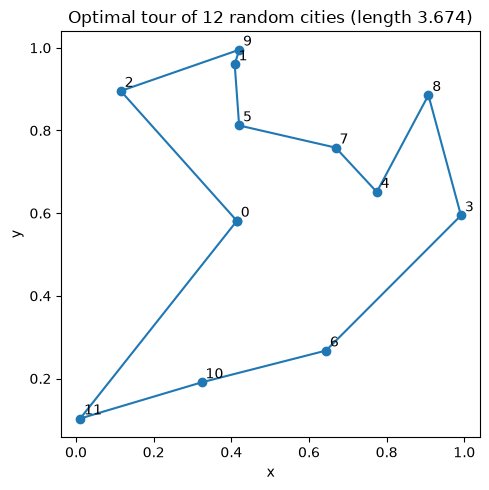

In [20]:
def held_karp(D):
    n = len(D)
    FULL = 1 << n
    dp = [[math.inf] * n for _ in range(FULL)]
    parent = [[-1] * n for _ in range(FULL)]
    dp[1][0] = 0                                        # mask 0b1 = {city 0}, standing at 0
    for mask in range(1, FULL):
        if not mask & 1:
            continue                                    # every path starts at city 0
        for j in range(n):
            if not mask >> j & 1 or dp[mask][j] == math.inf:
                continue
            for k in range(n):                          # push: extend the path to an unvisited k
                if mask >> k & 1:
                    continue
                new = mask | 1 << k
                cand = dp[mask][j] + D[j][k]
                if cand < dp[new][k]:
                    dp[new][k], parent[new][k] = cand, j
    last = min(range(n), key=lambda j: dp[FULL - 1][j] + D[j][0])
    best = dp[FULL - 1][last] + D[last][0]
    tour, mask, j = [], FULL - 1, last                  # reconstruct the tour backwards
    while j != -1:
        tour.append(j)
        mask, j = mask ^ (1 << j), parent[mask][j]
    return best, tour[::-1] + [0]


def tsp_brute(D):
    n = len(D)
    best = math.inf
    for perm in itertools.permutations(range(1, n)):
        tour = (0,) + perm + (0,)
        best = min(best, sum(D[tour[i]][tour[i + 1]] for i in range(n)))
    return best


def random_cities(n):
    pts = [(random.random(), random.random()) for _ in range(n)]
    D = [[math.dist(p, q) for q in pts] for p in pts]
    return pts, D


for n in range(2, 9):                                   # brute force up to n = 8 (5040 tours)
    for _ in range(5):
        _, D = random_cities(n)
        hk, tour = held_karp(D)
        assert abs(hk - tsp_brute(D)) < 1e-9
        assert abs(hk - sum(D[tour[i]][tour[i + 1]] for i in range(n))) < 1e-9
        assert sorted(tour[:-1]) == list(range(n))
print("Held-Karp matches brute force for n = 2..8 (5 random instances each)")

rows = []
for n in [6, 7, 8, 9, 10, 12]:
    pts, D = random_cities(n)
    t_hk = timed(held_karp, D, repeats=1)
    t_bf = timed(tsp_brute, D, repeats=1) if n <= 9 else None
    rows.append({"n": n, "(n-1)! tours": math.factorial(n - 1), "Held-Karp ms": round(t_hk * 1000, 1),
                 "brute force ms": round(t_bf * 1000, 1) if t_bf else "skipped (too slow)"})
    if n <= 9:
        assert abs(held_karp(D)[0] - tsp_brute(D)) < 1e-9
print(pd.DataFrame(rows).to_string(index=False))

best, tour = held_karp(D)                              # the n = 12 instance
plt.figure(figsize=(5, 5))
xs, ys = zip(*[pts[c] for c in tour])
plt.plot(xs, ys, "-o")
for c, (x, y) in enumerate(pts):
    plt.text(x + 0.01, y + 0.01, str(c))
plt.title(f"Optimal tour of 12 random cities (length {best:.3f})")
plt.xlabel("x"); plt.ylabel("y"); plt.tight_layout(); plt.show()

**What just happened?** Held-Karp equals brute force on every small instance and solves 12 cities in well under a second, while brute force grows factorially: it is already dozens of times slower at `n = 9`, and the `11! ≈ 40` million tours for `n = 12` would take minutes in Python. The optimal tour never crosses itself, a known property of optimal Euclidean tours.

The same bitmask trick works for any "best ordering / assignment of a small set" problem: assigning `n` tasks to `n` workers, covering a set with the fewest pieces, and so on, as long as `n` is around 20 or less.

## 8. DP on trees

> 💡 **In plain English:** on a tree, each node's answer is built from its children's answers, working upwards from the leaves.

On a tree, each node's subtree is a natural subproblem, and the children are independent of each other. The DP is computed **bottom-up from the leaves** with a post-order DFS.

**Maximum-weight independent set on a tree** ("house robber on a tree"): pick nodes with maximum total weight so that no two picked nodes are adjacent (e.g. invite employees to a party but never an employee together with their direct boss).

- **State:** for each node `v`: `take[v]` = best in `v`'s subtree if `v` is picked; `skip[v]` = best if `v` is not picked.
- **Transition:** `take[v] = w(v) + Σ skip[c]`, `skip[v] = Σ max(take[c], skip[c])` over children `c`.
- **Base:** leaves: `take = w(leaf)`, `skip = 0`. **Order:** post-order (children before parent). **Answer:** `max(take[root], skip[root])`.

On a general graph this problem is NP-hard; on a tree it is Θ(n).

tree DP matches brute force on 200 random trees (and the chosen set is independent)


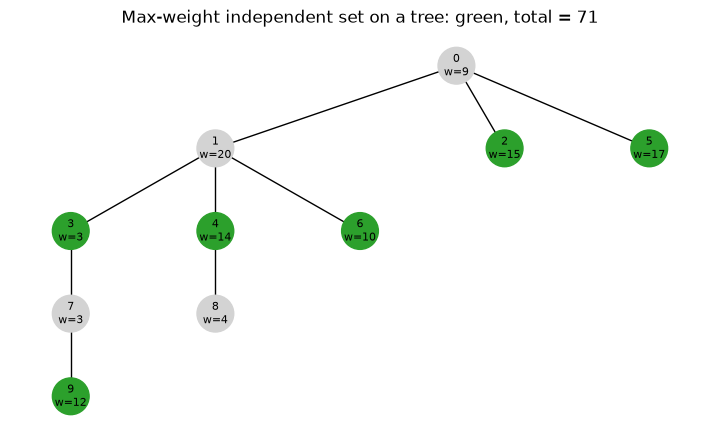

In [21]:
def tree_mwis(adj, weight, root=0):
    take, skip, chosen = {}, {}, set()
    def dfs(v, parent):                               # post-order: children first
        take[v], skip[v] = weight[v], 0
        for c in adj[v]:
            if c != parent:
                dfs(c, v)
                take[v] += skip[c]
                skip[v] += max(take[c], skip[c])
    dfs(root, None)
    def pick(v, parent, parent_taken):                # reconstruct the chosen set top-down
        use = (not parent_taken) and take[v] >= skip[v]
        if use:
            chosen.add(v)
        for c in adj[v]:
            if c != parent:
                pick(c, v, use)
    pick(root, None, False)
    return max(take[root], skip[root]), chosen


def random_tree(n):
    adj = {v: [] for v in range(n)}
    for v in range(1, n):
        u = random.randrange(v)                       # attach to an earlier node: always a tree
        adj[u].append(v); adj[v].append(u)
    return adj


def mwis_brute(adj, weight):
    n, best = len(adj), 0
    for mask in range(1 << n):
        if all(not (mask >> u & 1 and mask >> v & 1) for u in adj for v in adj[u]):
            best = max(best, sum(weight[v] for v in range(n) if mask >> v & 1))
    return best


for _ in range(200):
    n = random.randint(1, 12)
    adj = random_tree(n)
    w = [random.randint(1, 20) for _ in range(n)]
    val, chosen = tree_mwis(adj, w)
    assert val == mwis_brute(adj, w) == sum(w[v] for v in chosen)
    assert all(not (u in chosen and v in chosen) for u in adj for v in adj[u])
print("tree DP matches brute force on 200 random trees (and the chosen set is independent)")

adj = random_tree(10)
w = [random.randint(1, 20) for _ in range(10)]
val, chosen = tree_mwis(adj, w)
T = nx.Graph([(u, v) for u in adj for v in adj[u]])
def tree_layout(adj, root=0):
    # Top-down layout: leaves get consecutive x positions, parents sit above their children
    pos, next_x = {}, itertools.count()
    def place(v, parent, depth):
        kids = [c for c in adj[v] if c != parent]
        for c in kids:
            place(c, v, depth + 1)
        x = next(next_x) if not kids else sum(pos[c][0] for c in kids) / len(kids)
        pos[v] = (x, -depth)
    place(root, None, 0)
    return pos

pos = tree_layout(adj)
plt.figure(figsize=(7, 4))
nx.draw(T, pos, with_labels=False, node_size=700,
        node_color=["tab:green" if v in chosen else "lightgray" for v in T])
nx.draw_networkx_labels(T, pos, labels={v: f"{v}\nw={w[v]}" for v in T}, font_size=8)
plt.title(f"Max-weight independent set on a tree: green, total = {val}")
plt.show()

**What just happened?** The two-value DP (`take`/`skip`) per node matched brute force on 200 random trees, and the drawing shows a chosen set with no two adjacent green nodes. **Complexity:** Θ(n) time (each edge is processed once), Θ(n) space (recursion depth = tree height).

Other classic tree DPs: tree diameter, minimum vertex cover on a tree, counting subtrees, and "rerooting" techniques that compute an answer for every possible root in Θ(n).

## 9. 🔗 How DP connects to AI

> 💡 **In plain English:** DP sits inside speech recognition, spelling metrics, reinforcement learning and DNA alignment.

### 9a. Viterbi: the most likely hidden-state sequence in an HMM

A **hidden Markov model** (HMM) has hidden states (e.g. the weather: Hot/Cold) that emit observations (how many ice creams someone ate: 1, 2 or 3). Given the observations, the **Viterbi algorithm** finds the single most probable hidden-state sequence. Brute force would try all `Sᵀ` state sequences; Viterbi is a DP:

- **State:** `V[t][s]` = probability of the best state path that ends in state `s` at time `t` and explains observations `o₁..o_t`.
- **Transition:** `V[t][s] = max_{s'} V[t−1][s'] · P(s | s') · P(o_t | s)`; store the arg-max as a back-pointer.
- **Base:** `V[1][s] = π(s) · P(o₁ | s)`. **Answer:** `max_s V[T][s]`, then follow back-pointers.

Time Θ(T · S²) instead of Θ(Sᵀ · T). We use log-probabilities to avoid underflow. The same algorithm decoded speech in classic speech recognisers and tags parts of speech; see the HMM section of [`03_Machine_Learning/04_uncommon_models/01_uncommon_ml_models.ipynb`](../../03_Machine_Learning/04_uncommon_models/01_uncommon_ml_models.ipynb).

In [22]:
states = ["Hot", "Cold"]
start = {"Hot": 0.8, "Cold": 0.2}
trans = {"Hot": {"Hot": 0.6, "Cold": 0.4}, "Cold": {"Hot": 0.5, "Cold": 0.5}}
emit = {"Hot": {1: 0.2, 2: 0.4, 3: 0.4}, "Cold": {1: 0.5, 2: 0.4, 3: 0.1}}


def viterbi(obs):
    V = [{s: math.log(start[s]) + math.log(emit[s][obs[0]]) for s in states}]
    back = [{}]
    for t in range(1, len(obs)):
        V.append({}); back.append({})
        for s in states:
            prev, score = max(((p, V[t - 1][p] + math.log(trans[p][s])) for p in states), key=lambda x: x[1])
            V[t][s] = score + math.log(emit[s][obs[t]])
            back[t][s] = prev
    last = max(states, key=lambda s: V[-1][s])
    path = [last]
    for t in range(len(obs) - 1, 0, -1):
        path.append(back[t][path[-1]])
    return path[::-1], V[-1][last]


def viterbi_brute(obs):
    best = (None, -math.inf)
    for seq in itertools.product(states, repeat=len(obs)):
        lp = math.log(start[seq[0]]) + math.log(emit[seq[0]][obs[0]])
        for t in range(1, len(obs)):
            lp += math.log(trans[seq[t - 1]][seq[t]]) + math.log(emit[seq[t]][obs[t]])
        if lp > best[1]:
            best = (list(seq), lp)
    return best


obs = [3, 1, 3, 3, 1, 1, 2]
path, lp = viterbi(obs)
print("ice creams:", obs)
print("best path :", path, f"(log-prob {lp:.3f})")
for _ in range(200):
    o = [random.choice([1, 2, 3]) for _ in range(random.randint(1, 10))]
    p1, l1 = viterbi(o); p2, l2 = viterbi_brute(o)
    assert abs(l1 - l2) < 1e-9
print("Viterbi matches brute force over all 2^T state sequences on 200 random observation strings")

ice creams: [3, 1, 3, 3, 1, 1, 2]
best path : ['Hot', 'Cold', 'Hot', 'Hot', 'Cold', 'Cold', 'Hot'] (log-prob -10.391)


Viterbi matches brute force over all 2^T state sequences on 200 random observation strings


### 9b. Edit distance in NLP metrics: word error rate (WER)

Speech recognition and OCR systems are scored with **WER = (S + D + I) / N**: the word-level edit distance between the system output and the reference, divided by the number of reference words. Character error rate (CER) is the same at the character level. Our `edit_distance` works unchanged on lists of words. Edit distance also powers spelling correction and fuzzy matching; see [`07_NLP/08_speech_and_audio.ipynb`](../../07_NLP/08_speech_and_audio.ipynb) and [`08_LLM/08_evaluation/01_llm_evaluation.ipynb`](../../08_LLM/08_evaluation/01_llm_evaluation.ipynb).

In [23]:
reference = "the cat sat on the mat".split()
hypothesis = "the cat sit on mat".split()
errors = edit_distance(reference, hypothesis)[-1][-1]      # lists of words work as sequences
print(f"word-level edits: {errors}, reference words: {len(reference)}, WER = {errors / len(reference):.3f}")
_, top_, mid_, bot_ = alignment(reference, hypothesis)
print("alignment marks per word:", list(mid_))

word-level edits: 2, reference words: 6, WER = 0.333
alignment marks per word: ['|', '|', 's', '|', 'd', '|']


**What just happened?** One substitution (sat → sit) and one deletion (the second "the") give 2 errors over 6 reference words: WER = 0.333. (The `alignment` helper prints per-word marks because it walks the same table.)

### 9c. Bellman equations in reinforcement learning

Reinforcement learning is built on Bellman's own DP idea. The **Bellman optimality equation** says the value of a state is the best immediate reward plus the discounted value of where you land:

`V*(s) = max_a Σ_{s'} P(s' | s, a) · [ R(s, a, s') + γ · V*(s') ]`

**Value iteration** turns this recurrence into a DP: start with `V = 0` and apply the equation to every state repeatedly until nothing changes. In a deterministic grid where every move costs −1 and `γ = 1`, `V*(s)` must equal minus the shortest-path distance to the goal, which we can check with BFS.

In [24]:
from collections import deque

grid = ["....#",
        ".##.#",
        "....G",
        "#.#..",
        "....."]
R, C = len(grid), len(grid[0])
cells = [(r, c) for r in range(R) for c in range(C) if grid[r][c] != "#"]
goal = next((r, c) for r, c in cells if grid[r][c] == "G")
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def step(s, m):
    r, c = s[0] + m[0], s[1] + m[1]
    return (r, c) if 0 <= r < R and 0 <= c < C and grid[r][c] != "#" else s   # walls: stay put

V = {s: 0.0 for s in cells}
for sweep in range(100):
    newV = {s: 0.0 if s == goal else max(-1 + V[step(s, m)] for m in moves) for s in cells}   # Bellman update
    if newV == V:
        break
    V = newV
print("value iteration converged after", sweep, "sweeps")

dist = {goal: 0}                                  # BFS from the goal for comparison
q = deque([goal])
while q:
    s = q.popleft()
    for m in moves:
        n_ = step(s, m)
        if n_ not in dist:
            dist[n_] = dist[s] + 1; q.append(n_)
assert all(V[s] == -dist[s] for s in cells)
print(pd.DataFrame([[("#" if grid[r][c] == "#" else int(V[(r, c)])) for c in range(C)] for r in range(R)]))
print("V*(s) = -(shortest distance to G) for every cell, as predicted")

value iteration converged after 6 sweeps
    0   1   2  3   4
0  -6  -5  -4 -3   #
1  -5   #   # -2   #
2  -4  -3  -2 -1   0
3   #  -4   # -2  -1
4  -6  -5  -4 -3  -2
V*(s) = -(shortest distance to G) for every cell, as predicted


**What just happened?** Repeatedly applying the Bellman update converged to values that are exactly minus the BFS distance to the goal. The same DP, with probabilities and discounting, is policy evaluation and value iteration in [`11_Reinforcement_Learning/02_dynamic_programming.ipynb`](../../11_Reinforcement_Learning/02_dynamic_programming.ipynb); Q-learning and deep Q-networks are sample-based approximations of it.

### 9d. More DP inside modern AI

- **Sequence alignment in bioinformatics:** Needleman-Wunsch (global) and Smith-Waterman (local) alignment are edit distance with biological scoring matrices and gap penalties. Protein-structure models such as AlphaFold start from multiple sequence alignments built with such tools.
- **Dynamic time warping (DTW)** aligns two time series of different speeds with an edit-distance-like table, used for gesture and speech matching and time-series classification.
- **CTC loss** (speech recognition, handwriting OCR) sums over all alignments between audio frames and labels with a forward-backward DP; the **forward algorithm** of HMMs is Viterbi with `max` replaced by `+`.
- **Beam search** in LLM decoding is a pruned, approximate version of this kind of search: exact DP over all token sequences is impossible because the state (the whole prefix) never repeats; see [`07_NLP/05_language_models_and_generation.ipynb`](../../07_NLP/05_language_models_and_generation.ipynb).
- **Parsing:** the CYK algorithm parses context-free grammars with an interval DP very similar to matrix-chain multiplication.

## 10. Recap

> 💡 **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- DP = **optimal substructure + overlapping subproblems**: solve each subproblem once and store it.
- **Top-down memoisation** keeps the recursion and adds a cache (watch Python's recursion limit); **bottom-up tabulation** fills a table in dependency order and allows **space optimisation**.
- Use the recipe every time: **state** (in words), **transition**, **base case**, **order**, **answer**; complexity = states × work per state.
- Patterns: 1-D over prefixes (stairs, robber, coins, decode ways, word break); 2-D grids; two sequences (LCS, edit distance); **interval DP** (matrix chain, LPS); **knapsack-style** with downward iteration (0/1 knapsack, partition); **bitmask DP** over subsets (TSP); **tree DP** in post-order.
- Reconstruct the actual solution by storing or re-deriving the choices (back-pointers).
- Knapsack, coin change and subset sum are **pseudo-polynomial**; TSP stays exponential even with DP (Θ(2ⁿn²)).
- In AI: Viterbi (HMMs), WER/CER metrics, Bellman equations and value iteration, sequence alignment, DTW, CTC, CYK.

## Practice problems

**1. (Easy, conceptual)** For "minimum cost climbing stairs" (`cost[i]` to step on stair `i`, climb 1 or 2 at a time, start at stair 0 or 1, reach just past the last stair), write the state, transition, base cases and answer.

<details><summary>Show solution</summary>

State `dp[i]` = minimum cost to stand on position `i` (positions `0..n`, where `n` is "past the top"). Transition `dp[i] = min(dp[i−1] + cost[i−1], dp[i−2] + cost[i−2])`. Base `dp[0] = dp[1] = 0` (you may start at either). Answer `dp[n]`.

```python
def min_cost_stairs(cost):
    a, b = 0, 0                                   # dp[i-2], dp[i-1]
    for i in range(2, len(cost) + 1):
        a, b = b, min(b + cost[i - 1], a + cost[i - 2])
    return b
assert min_cost_stairs([10, 15, 20]) == 15
assert min_cost_stairs([1, 100, 1, 1, 1, 100, 1, 1, 100, 1]) == 6
```
</details>

**2. (Easy, conceptual)** Why does the 1-D 0/1 knapsack loop over capacities **downward**? What problem do you solve if you loop upward?

<details><summary>Show solution</summary>

`dp[c − w]` must still hold the value from the *previous* item round. Going downward, `dp[c − w]` has not been updated for the current item yet. Going upward, it may already include the current item, so the item can be taken repeatedly: that is the **unbounded** knapsack.
</details>

**3. (Medium, coding)** Longest common **substring** (contiguous). Return its length.

<details><summary>Show solution</summary>

State `dp[i][j]` = length of the longest common suffix of `a[:i]` and `b[:j]`; `dp[i][j] = dp[i−1][j−1] + 1` if the characters match, else 0. The answer is the maximum entry.

```python
def longest_common_substring(a, b):
    best, prev = 0, [0] * (len(b) + 1)
    for i in range(1, len(a) + 1):
        cur = [0] * (len(b) + 1)
        for j in range(1, len(b) + 1):
            if a[i - 1] == b[j - 1]:
                cur[j] = prev[j - 1] + 1
                best = max(best, cur[j])
        prev = cur
    return best
assert longest_common_substring("ABABC", "BABCA") == 4      # "BABC"
```
</details>

**4. (Medium, coding)** Minimum number of characters to **insert** to make a string a palindrome.

<details><summary>Show solution</summary>

Answer = `len(s) − LPS(s)`: keep the longest palindromic subsequence and insert a mirror for every other character. With the `lps` function above: `len("mbadm") − lps("mbadm")[0] = 5 − 3 = 2` ("mbdadbm"); `"leetcode"` needs 5.
</details>

**5. (Medium, conceptual)** Fibonacci's memoised version uses O(n) space, the tabulated O(1) version uses O(1). Can every DP be space-optimised to keep only "the last row"? Give an example where you lose something.

<details><summary>Show solution</summary>

You can keep only the rows that the transition reads. For LCS or knapsack this gives the *value* in Θ(n) or Θ(W) space, but you lose the full table needed to **reconstruct** the subsequence or the chosen items. (Hirschberg's algorithm recovers the LCS in linear space with a divide-and-conquer trick, at about twice the time.) Interval DPs such as matrix chain need the whole table because `m[i][j]` reads all shorter intervals.
</details>

**6. (Hard, coding)** Count the number of **ordered** ways to reach a total of `n` using steps from a list `steps` (e.g. steps (1, 3, 5)). Then explain why this is "coin change with the loops swapped".

<details><summary>Show solution</summary>

```python
def ordered_ways(n, steps):
    dp = [1] + [0] * n
    for i in range(1, n + 1):                  # total outside
        dp[i] = sum(dp[i - s] for s in steps if s <= i)
    return dp[n]
assert ordered_ways(5, [1, 3, 5]) == 5         # 11111, 113, 131, 311, 5
```
With the total in the outer loop, `dp[i]` adds up sequences by their **last** step, so different orders are different sequences. With the coin in the outer loop (`count_ways`), each coin type is introduced once, so each multiset is counted once.
</details>

**7. (Hard, coding)** Assignment problem with bitmask DP: `cost[i][j]` is the cost of giving job `j` to worker `i` (`n ≤ 12`). Find the minimum total cost when each worker gets exactly one job.

<details><summary>Show solution</summary>

State `dp[mask]` = minimum cost after the first `popcount(mask)` workers have been given the jobs in `mask`. Transition: the next worker `i = popcount(mask)` takes any free job `j`.

```python
import itertools, random
def assignment(cost):
    n = len(cost)
    dp = [float("inf")] * (1 << n)
    dp[0] = 0
    for mask in range(1 << n):
        i = bin(mask).count("1")               # next worker to assign
        if i == n:
            continue
        for j in range(n):
            if not mask >> j & 1:
                dp[mask | 1 << j] = min(dp[mask | 1 << j], dp[mask] + cost[i][j])
    return dp[(1 << n) - 1]

for _ in range(50):
    n = random.randint(1, 6)
    c = [[random.randint(1, 20) for _ in range(n)] for _ in range(n)]
    brute = min(sum(c[i][p[i]] for i in range(n)) for p in itertools.permutations(range(n)))
    assert assignment(c) == brute
```
Θ(2ⁿ · n) time instead of Θ(n!). (The Hungarian algorithm solves it in Θ(n³), but the bitmask pattern generalises to many problems without such a special algorithm.)
</details>

## Further reading

- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS), 4th ed., ch. 14 "Dynamic Programming" (rod cutting, matrix chain, LCS, optimal BSTs).
- Kleinberg and Tardos, *Algorithm Design*, ch. 6 (weighted interval scheduling, knapsack, sequence alignment, Bellman-Ford).
- Jurafsky and Martin, *Speech and Language Processing* (3rd ed. draft, free online): minimum edit distance (ch. 2) and HMMs/Viterbi (appendix A).
- Sutton and Barto, *Reinforcement Learning: An Introduction*, 2nd ed. (free online), ch. 4 "Dynamic Programming".
- GeeksforGeeks "Dynamic Programming" tutorial for hundreds of extra practice problems.

## Next notebook

Continue with [`10_backtracking.ipynb`](10_backtracking.ipynb): backtracking, the systematic way to search *all* solutions when there is no overlapping-subproblem structure to exploit.